In [199]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import warnings
warnings.filterwarnings('ignore')


# Dataset Loading

In this section, we locate the dataset files available in the Kaggle environment. This step helps us identify the file path before loading the SMS Spam Collection dataset into our project.

In [200]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename.lower().endswith('.csv'):
            print(os.path.join(dirname, filename))

/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv


# Loading the Dataset

In this step, we load the SMS Spam Collection dataset using Pandas. The dataset contains SMS messages labeled as either spam or ham. We will use these messages to build our binary classification model.

In [201]:
df = pd.read_csv("/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv", encoding="latin-1")

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


# Data Exploration

In this section, we will explore the dataset structure, column names, and missing values to understand the data before preprocessing.

In [202]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (5572, 5)

Column Names:
Index(['v1', 'v2', 'Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

Missing Values:
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64


# Data Cleaning and Preprocessing

In this section, we will remove unnecessary columns, keep the SMS labels and message text, and convert the labels into numerical values for Logistic Regression.

In [203]:
# Keep only the required columns
df = df[['v1', 'v2']].copy()

# Rename columns
df.columns = ['label', 'message']

# Convert labels into numerical values
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

# Display the cleaned dataset
print(df.head())

print("\nClass Distribution:")
print(df['label'].value_counts())

   label                                            message
0      0  Go until jurong point, crazy.. Available only ...
1      0                      Ok lar... Joking wif u oni...
2      1  Free entry in 2 a wkly comp to win FA Cup fina...
3      0  U dun say so early hor... U c already then say...
4      0  Nah I don't think he goes to usf, he lives aro...

Class Distribution:
label
0    4825
1     747
Name: count, dtype: int64


# Train-Test Split

In this section, we will split the dataset into training and testing sets. We will use 80% of the data for training and 20% for testing while maintaining the same class distribution.

In [204]:
X = df['message']
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


# Text Vectorization using TF-IDF

In this section, we will convert SMS messages into numerical features using TF-IDF. This allows the Logistic Regression model to process text data. We will fit the vectorizer on the training data and apply it to the testing data.

In [205]:
tfidf = TfidfVectorizer(max_features=3000)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training data shape:", X_train_tfidf.shape)
print("Testing data shape:", X_test_tfidf.shape)

Training data shape: (4457, 3000)
Testing data shape: (1115, 3000)


# Logistic Regression Model

In this section, we will implement Logistic Regression from scratch. We will define the Sigmoid function to calculate probabilities and the Binary Cross-Entropy Loss to measure prediction errors. These functions will be used by all five optimization algorithms.

In [206]:
# Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Binary Cross-Entropy Loss
def compute_loss(y_true, y_pred):
    epsilon = 1e-15
    y_pred = np.clip(y_pred, epsilon, 1 - epsilon)

    loss = -np.mean(
        y_true * np.log(y_pred) +
        (1 - y_true) * np.log(1 - y_pred)
    )

    return loss


# Calculate Gradients
def compute_gradients(X, y, weights, bias):
    n = X.shape[0]

    predictions = sigmoid(X @ weights + bias)
    errors = predictions - y

    dw = np.asarray(X.T @ errors).ravel() / n
    db = np.mean(errors)

    return dw, db

### 1. Gradient Descent (GD) with Momentum

In this section, we will implement Gradient Descent with Momentum to update the model weights and bias in order to minimize the Binary Cross-Entropy Loss.

In [207]:
def train_gd_momentum(X, y, learning_rate=0.01, momentum=0.9, epochs=1000):

    n_samples, n_features = X.shape

    weights = np.zeros(n_features)
    bias = 0.0

    velocity_w = np.zeros(n_features)
    velocity_b = 0.0

    losses = []

    for epoch in range(epochs):

        predictions = sigmoid(X @ weights + bias)

        dw, db = compute_gradients(X, y, weights, bias)

        velocity_w = momentum * velocity_w + learning_rate * dw
        velocity_b = momentum * velocity_b + learning_rate * db

        weights -= velocity_w
        bias -= velocity_b

        loss = compute_loss(y, sigmoid(X @ weights + bias))
        losses.append(loss)

    return weights, bias, losses

In [208]:
weights_gd, bias_gd, losses_gd = train_gd_momentum(
    X_train_tfidf,
    y_train.to_numpy(),
learning_rate=0.1,
    momentum=0.9,
    epochs=1000
)

print("Final Training Loss:", losses_gd[-1])

Final Training Loss: 0.1604286301054093


# Model Evaluation
 
In this section, we will use the trained Logistic Regression model to predict the labels of the test messages and evaluate its performance using Accuracy, Precision, Recall, F1-score, and Binary Cross-Entropy Loss.

In [209]:
y_test_array = y_test.to_numpy()

# Predict probabilities
y_prob_gd = sigmoid(X_test_tfidf @ weights_gd + bias_gd)

# Convert probabilities into class predictions
y_pred_gd = (y_prob_gd >= 0.5).astype(int)

# Calculate evaluation metrics
print("Accuracy:", accuracy_score(y_test_array, y_pred_gd))
print("Precision:", precision_score(y_test_array, y_pred_gd, zero_division=0))
print("Recall:", recall_score(y_test_array, y_pred_gd, zero_division=0))
print("F1 Score:", f1_score(y_test_array, y_pred_gd, zero_division=0))
print("Test Loss:", compute_loss(y_test_array, y_prob_gd))

Accuracy: 0.9497757847533632
Precision: 0.9894736842105263
Recall: 0.6308724832214765
F1 Score: 0.7704918032786885
Test Loss: 0.1633186727821736


In [210]:
print("Predicted Classes:")
print(pd.Series(y_pred_gd).value_counts())

print("\nActual Classes:")
print(y_test.value_counts())

Predicted Classes:
0    1020
1      95
Name: count, dtype: int64

Actual Classes:
label
0    966
1    149
Name: count, dtype: int64


In [211]:
print("Minimum probability:", y_prob_gd.min())
print("Maximum probability:", y_prob_gd.max())
print("Average probability:", y_prob_gd.mean())

Minimum probability: 0.014816666740016284
Maximum probability: 0.9026053159637751
Average probability: 0.13451213357761596


In [212]:
y_train_prob = sigmoid(X_train_tfidf @ weights_gd + bias_gd)
y_train_pred = (y_train_prob >= 0.5).astype(int)

print("Predicted Training Classes:")
print(pd.Series(y_train_pred).value_counts())

print("\nActual Training Classes:")
print(y_train.value_counts())

Predicted Training Classes:
0    4101
1     356
Name: count, dtype: int64

Actual Training Classes:
label
0    3859
1     598
Name: count, dtype: int64


### Training Loss Curve

In this section, we will visualize the Binary Cross-Entropy Loss over the training epochs to observe how the model learns and converges.

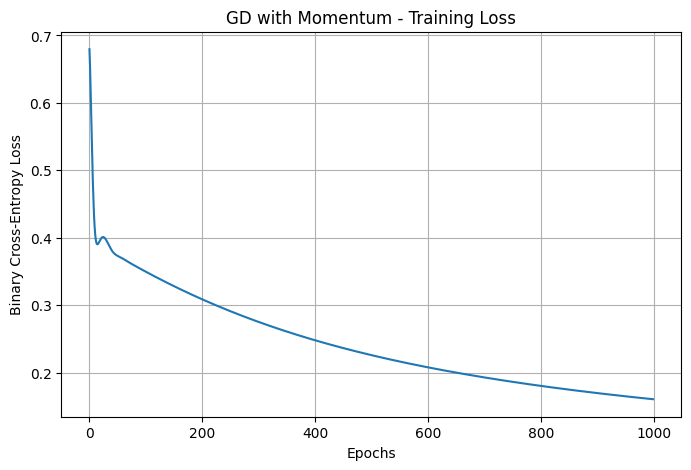

In [213]:
plt.figure(figsize=(8, 5))
plt.plot(losses_gd)

plt.title("GD with Momentum - Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Binary Cross-Entropy Loss")
plt.grid(True)
plt.show()

The training loss curve shows a steady decrease in Binary Cross-Entropy Loss over 1000 epochs. This indicates that the GD with Momentum optimizer successfully learns the model parameters and gradually improves the model's performance.

In [215]:
gd_results = pd.DataFrame({
    'Parameter': [
        'Optimizer',
        'Learning Rate',
        'Momentum',
        'Epochs',
        'Training Loss',
        'Test Loss',
        'Accuracy',
        'Precision',
        'Recall',
        'F1 Score'
    ],
    'Value': [
        'GD with Momentum',
        0.1,
        0.9,
        1000,
        losses_gd[-1],
        compute_loss(y_test_array, y_prob_gd),
        accuracy_score(y_test_array, y_pred_gd),
        precision_score(y_test_array, y_pred_gd, zero_division=0),
        recall_score(y_test_array, y_pred_gd, zero_division=0),
        f1_score(y_test_array, y_pred_gd, zero_division=0)
    ]
})

gd_results

,Parameter,Value
0,Optimizer,GD with Momentum
1,Learning Rate,0.1
2,Momentum,0.9
3,Epochs,1000
4,Training Loss,0.160429
5,Test Loss,0.163319
6,Accuracy,0.949776
7,Precision,0.989474
8,Recall,0.630872
9,F1 Score,0.770492
